# 03 · Silver

## 0. Ejecución y determinismo

In [1]:
"""
Aquí lo primero que hicimos fue correr la transformación completa dos veces seguidas desde el notebook, llamando a la misma
función que usa main.py, y comparar el sha256 de cada archivo de Silver entre una corrida y la otra. Lo hicimos así porque una regla del proyecto
exige que Silver sea determinista, o sea, sin fechas de ejecución adentro y con orden estable. La salida debería mostrar que todos los
hashes coinciden y que Bronze sigue intacto contra el manifiesto. Esto prueba la repetibilidad del proceso, pero no que las reglas
estén bien; eso lo vamos revisando en las secciones siguientes.
"""
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.common import ROOT, load_config, read_manifest, sha256_file
from src.transform.integrate import run_transform, validar_llave

cfg = load_config(); P = cfg['paths_silver']
archivos = [P[k] for k in ('construcciones', 'estrato_barrio', 'integrated', 'orphans_left', 'orphans_right', 'quality_report')] + ['docs/silver/validacion_llave.md', 'docs/silver/reglas_silver.md']
run_transform(); h1 = {a: sha256_file(ROOT / a) for a in archivos}
run_transform(); h2 = {a: sha256_file(ROOT / a) for a in archivos}
print(pd.DataFrame({'sha256 (corrida 1)': {a: h[:14] + '…' for a, h in h1.items()}, 'idéntico en corrida 2': {a: h1[a] == h2[a] for a in archivos}}))
print('Bronze intacto contra el manifiesto:', all(sha256_file(ROOT / m['path']) == m['sha256'] for m in read_manifest()))


2026-10-16 14:47:42 INFO etl.integrate Inicio etapa transform


2026-10-16 14:47:42 INFO etl.integrate Entrada: 5146 construcciones y 369 filas del CSV de estrato


2026-10-16 14:47:43 INFO etl.integrate Salida: construcciones=5146 barrios=346 integrado=5146 | cobertura de llave=99.8834% (pasa) | huérfanos izquierda=6 derecha=295


2026-10-16 14:47:43 INFO etl.integrate llave_confianza=alta (nombre validado 93.52%) | hallazgos faltantes: ninguno


2026-10-16 14:47:43 WARNING etl.integrate 6 construcciones sin llave en el JOIN (COMUNA o BARRIO en blanco: 2; código ausente del CSV 2015: 4)


2026-10-16 14:47:43 WARNING etl.integrate 18 construcciones con geometría idéntica a otra (marcadas, no eliminadas)


... (5 outputs left out)

2026-10-16 14:47:43 WARNING etl.integrate 6 construcciones sin llave en el JOIN (COMUNA o BARRIO en blanco: 2; código ausente del CSV 2015: 4)


2026-10-16 14:47:43 WARNING etl.integrate 18 construcciones con geometría idéntica a otra (marcadas, no eliminadas)


2026-10-16 14:47:43 INFO etl.integrate Fin etapa transform (0.68 s)


                                      sha256 (corrida 1)  \
data/silver/silver_construcciones.csv    85ea33ebe99c9f…   
data/silver/silver_estrato_barrio.csv    0815be18476695…   
data/silver/silver_integrated.csv        bc1d1c6bd4bb3f…   
data/silver/silver_orphans_left.csv      04bc074bf0332e…   
data/silver/silver_orphans_right.csv     da95c33f59f511…   
data/silver/quality_report.json          fa66f7f26ff6b6…   
docs/validacion_llave.md                 d63a5bd5b5be57…   
docs/reglas_silver.md                    aa232c2fc72d0c…   

                                       idéntico en corrida 2  
data/silver/silver_construcciones.csv                   True  
data/silver/silver_estrato_barrio.csv                   True  
data/silver/silver_integrated.csv                       True  
data/silver/silver_orphans_left.csv                     True  
data/silver/silver_orphans_right.csv                    True  
data/silver/quality_report.json                         True  
docs/validacion_ll

## 1. Antes y después, y reglas aplicadas

In [2]:
"""
En esta celda comparamos la forma de los datos antes y después de limpiar: filas, columnas y nulos de las construcciones. Cargamos el
reporte de calidad que genera el pipeline en lugar de recalcular todo a mano, para que el notebook y los archivos digan lo mismo.
Notamos que las filas no cambian (5.146 de entrada y 5.146 de salida) porque nuestra decisión fue no eliminar nada sin hallazgo; lo que
sí cambia son las columnas, que pasan de 20 a 18, y los textos vacíos que ahora son nulos de verdad. Esto no dice que los datos estén
correctos, solo que las transformaciones fueron las que documentamos en cada regla.
"""
rep = json.loads((ROOT / P['quality_report']).read_text(encoding='utf-8'))
cons = pd.read_csv(ROOT / P['construcciones'], dtype={'comuna': str, 'barrio': str, 'codigo_barrio': str, 'codigo_poligono': str})
print('filas entrada/salida:', rep['fuentes']['construcciones'], '| columnas Silver:', cons.shape[1])
antes = pd.Series(rep['nulos_antes_bronze']); despues = pd.Series(rep['nulos_despues_construcciones'])
print(pd.DataFrame({'nulos o vacíos antes (Bronze)': antes, 'nulos después (Silver)': despues}).fillna('(descartada)').head(25))
reglas = pd.DataFrame(rep['reglas_aplicadas'])[['id', 'hallazgo', 'columnas', 'filas_afectadas']]
pd.set_option('display.width', 200, 'display.max_colwidth', 70, 'display.max_columns', 30)
print(reglas)


filas entrada/salida: {'filas_entrada': 5146, 'filas_salida': 5146} | columnas Silver: 18
                   nulos o vacíos antes (Bronze) nulos después (Silver)
BARRIO                                       2.0           (descartada)
COMUNA                                       2.0           (descartada)
COND                                       197.0           (descartada)
DEPAPRED                                     1.0           (descartada)
EDIFPRED                                  4097.0           (descartada)
Estado_Estructural                           0.0           (descartada)
ID_PREDIO                                 1509.0           (descartada)
Indice_Escombros                           435.0           (descartada)
MANZANA                                      2.0           (descartada)
MUNIPRED                                    10.0           (descartada)
NPISOS                                      11.0           (descartada)
NUMEPRED                                  2908

## 2. Duplicados y llaves

In [3]:
"""
Aquí verificamos con pandas, y no solo con los aserts del código, que no queden duplicados por la llave natural en ninguna de las tres
tablas: OBJECTID en construcciones, código de barrio en el CSV limpio y OBJECTID en la tabla integrada. También contamos las
geometrías duplicadas, que decidimos marcar y no borrar porque no tenemos evidencia de que sean doble conteo. La salida muestra cero
duplicados en las tres tablas y 18 construcciones marcadas, que son 9 pares. Lo que esto NO demuestra es que no haya duplicados
semánticos, por ejemplo dos huellas distintas del mismo edificio, eso no lo podemos detectar con estos datos.
"""
barr = pd.read_csv(ROOT / P['estrato_barrio'], dtype={'codigo_barrio': str})
integ = pd.read_csv(ROOT / P['integrated'], dtype={'comuna': str, 'barrio': str, 'codigo_barrio': str, 'codigo_poligono': str})
print('duplicados por objectid (construcciones):', int(cons.objectid.duplicated().sum()))
print('duplicados por codigo_barrio (CSV limpio):', int(barr.codigo_barrio.duplicated().sum()))
print('duplicados por objectid (integrado):', int(integ.objectid.duplicated().sum()), '| filas:', len(integ))
print('construcciones con geometría idéntica a otra (marcadas):', int(cons.geom_duplicada.sum()), '= pares:', int(cons.geom_duplicada.sum() // 2))
print('barrios sin mojibake (Ã o �) en el CSV limpio:', not barr.barrio.str.contains('Ã|\ufffd').any())


duplicados por objectid (construcciones): 0
duplicados por codigo_barrio (CSV limpio): 0
duplicados por objectid (integrado): 0 | filas: 5146
construcciones con geometría idéntica a otra (marcadas): 18 = pares: 9
barrios sin mojibake (Ã o �) en el CSV limpio: True


## 3. Cobertura del JOIN y huérfanos

In [4]:
"""
Acá calculamos las dos coberturas que separamos desde el EDA, con numerador y denominador: la de la llave, que es la que se compara
contra el umbral de 80 % de la configuración, y la del estrato válido, que además excluye los barrios NR. Después miramos los huérfanos
de cada lado. A la izquierda quedan 6 construcciones, 4 con el código 1920 que no existe en el CSV de 2015 y 2 con comuna y barrio en
blanco. A la derecha quedan 295 barrios del CSV que no tienen ninguna construcción, lo cual es esperable porque la capa solo cubre 7
comunas. La salida muestra que el umbral se cumple de sobra; no dice que los 295 barrios no afectados estén libres de daño.
"""
print('cobertura de llave:', rep['cobertura_llave'], '| umbral', rep['umbral_cobertura_join'], '->', rep['resultado_umbral'])
print('cobertura de estrato válido:', rep['cobertura_estrato_valido'])
print('sin estrato válido:', rep['sin_estrato_valido'])
ol = pd.read_csv(ROOT / P['orphans_left'], dtype=str)
print(ol[['objectid', 'comuna', 'barrio', 'codigo_barrio', 'codigo_poligono', 'nombre_poligono', 'causa']].fillna('(vacío)'))
orr = pd.read_csv(ROOT / P['orphans_right'], dtype={'codigo_barrio': str})
print('barrios del CSV sin construcciones:', len(orr), '| con más lados de manzana (los más grandes):')
print(orr.sort_values('lados_total', ascending=False)[['codigo_barrio', 'barrio', 'lados_total', 'estrato']].head(6))


cobertura de llave: {'num': 5140, 'den': 5146, 'pct': 0.998834} | umbral 0.8 -> pasa
cobertura de estrato válido: {'num': 5138, 'den': 5146, 'pct': 0.998445}
sin estrato válido: {'total': 8, 'sin_llave': 6, 'moda_NR': 2}
  objectid   comuna   barrio codigo_barrio codigo_poligono                         nombre_poligono                        causa
0       71       19       20          1920            1933  Sector Unidad Deportiva Jaime Aparicio  código ausente del CSV 2015
1     1683       19       20          1920            1933  Sector Unidad Deportiva Jaime Aparicio  código ausente del CSV 2015
2     1821  (vacío)  (vacío)       (vacío)            1913                                El Cedro    COMUNA o BARRIO en blanco
3     2494  (vacío)  (vacío)       (vacío)            2001                              El Cortijo    COMUNA o BARRIO en blanco
4     2524       19       20          1920            1933  Sector Unidad Deportiva Jaime Aparicio  código ausente del CSV 2015
5     5002 

## 4. Validación semántica de la llave

In [5]:
"""
Esta es la sección donde le ponemos a prueba a la llave. Para cada código derivado de comuna y barrio comparamos el nombre que
trae el CSV de 2015 contra el nombre del polígono de 2026 donde caen sus construcciones, usando una similitud de texto con umbral
de 0,85, y pusimos el resultado como una bandera, nombre_validado. Vimos que 44 de 51 códigos coinciden y que el 93,5 % de las
construcciones quedan en códigos validados, por eso la confianza sale alta. Los 7 que fallan son casi todos diferencias de prefijo
como Barrio Caldas contra Caldas. Esto NO demuestra que la llave sea perfecta: un nombre parecido no garantiza que sea el mismo
barrio, y no cambiamos la llave ni creamos alias para que la cifra suba.
"""
def bool_(s): return s.map({'True': True, 'False': False}).astype('boolean')
iv = integ.copy(); iv['cruza_llave'] = bool_(iv.cruza_llave.astype(str)); iv['coincide_poligono'] = bool_(iv.coincide_poligono.astype(str))
val = validar_llave(iv, cfg['llave']['similitud_nombre_min'])
print('códigos validados:', int(val.nombre_validado.sum()), 'de', len(val), '| llave_confianza:', rep['llave_confianza'])
print('pct_coincide_poligono:', rep['pct_coincide_poligono'])
print('pct_nombre_validado:', json.dumps(rep['pct_nombre_validado']))
print(val[~val.nombre_validado][['codigo_barrio', 'n_construcciones', 'nombre_csv', 'nombre_poligono', 'similitud', 'pct_coincide_poligono']])
print('códigos con 0 % de coincidencia con el polígono (H13), de los que cruzan el CSV:', int((val.pct_coincide_poligono == 0).sum()), '+ 1920 huérfano')


códigos validados: 44 de 51 | llave_confianza: alta
pct_coincide_poligono: {'num': 4703, 'den': 5144, 'pct': 0.914269}
pct_nombre_validado: {"global": {"num": 4807, "den": 5140, "pct": 0.935214}, "coincide_poligono_true": {"num": 4391, "den": 4703, "pct": 0.933659}, "coincide_poligono_false": {"num": 416, "den": 437, "pct": 0.951945}}
   codigo_barrio  n_construcciones                      nombre_csv                                         nombre_poligono  similitud  pct_coincide_poligono
10          1011                55            Barrio Departamental                                           Departamental     0.7879                    1.0
17          1802                 9                   Barrio Caldas                                                  Caldas     0.6316                    1.0
21          1898                 3                    Alto Nápoles                                     Sector Alto Nápoles     0.7742                    0.0
25          1905               177 

In [6]:
"""
Aquí cerramos dos verificaciones pequeñas que nos pidieron sobre el CSV. La primera es que tratar los vacíos de los lados de manzana
como cero no cambie el estrato moda del barrio; hay dos barrios con un vacío, uno en la columna de lados del estrato 1 y otro en la del estrato 4, y vimos que en ambos
casos el estrato moda es también el que tiene más lados. La segunda es confirmar que los dos Camino Real son barrios distintos, con
códigos y nombres diferentes. La salida lo muestra con cifras. Esto no prueba que el vacío fuera realmente un cero, solo que, sea
cero o no, no cambia la decisión de estrato en esos barrios.
"""
print(pd.DataFrame(rep['verificaciones_csv']['vacios_tratados_como_cero']))
print('Camino Real (código, nombre):', rep['verificaciones_csv']['camino_real'])
print('¿son distintos?', len({c for c, _ in rep['verificaciones_csv']['camino_real']}) == len(rep['verificaciones_csv']['camino_real']))


    columna codigo_barrio                 barrio  estrato_moda  estrato_con_mas_lados  lados_total  sin_cambio
0  lados_e1          5607  El Mango - La Reforma             2                      2           19        True
1  lados_e4           202         Santa Teresita             6                      6           58        True
Camino Real (código, nombre): [['1922', 'Camino Real J. Borrero S.'], ['1923', 'Camino Real Los Fundadores']]
¿son distintos? True


## 5. Variable de daño y tamaño de muestra

        n  sin_datos  pct_sin_datos  n_con_datos  k_severos  pct_severo  muestra_baja (<30 severos)
1   338.0       36.0       0.106509        302.0       20.0        6.62                        True
2   126.0       34.0       0.269841         92.0        3.0        3.26                        True
3  1282.0      109.0       0.085023       1173.0       74.0        6.31                       False
4  2267.0      172.0       0.075871       2095.0      145.0        6.92                       False
5  1114.0       83.0       0.074506       1031.0       53.0        5.14                       False
6    11.0        0.0       0.000000         11.0        0.0        0.00                        True
techo sobre construcciones con datos: 22.5 % | severo_estricto: 296 | dano_visible: 1354 | con datos: 4711


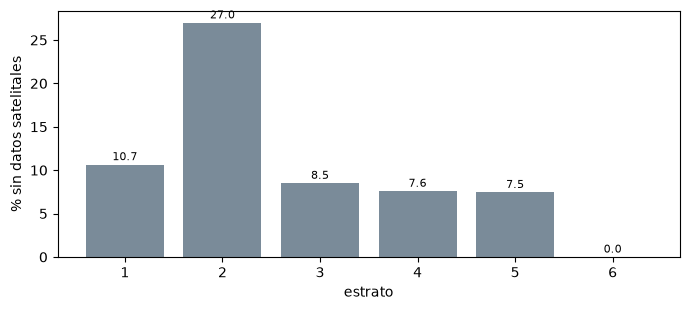

In [7]:
"""
Ahora resumimos la variable de daño con los conteos que ya trae el reporte. Fijamos como indicador principal el severo estricto, o sea la
clase de alta probabilidad de escombros, y dejamos el daño visible como sensibilidad de baja confianza. La razón es que las imágenes son
del 22 de marzo y del 11 de agosto, unos cuatro meses y medio, sin grupo de control, y los techos desaparecidos suman 22,5 % de las
construcciones con datos, lo cual no se puede atribuir solo al sismo. Es una limitación, no una regla de limpieza. La tabla muestra
n, severos, porcentaje sin datos y la alerta de muestra baja por estrato; no permite concluir diferencias entre estratos.
"""
est = pd.DataFrame(rep['sin_datos']['por_estrato']).T[['n', 'sin_datos', 'pct_sin_datos', 'n_con_datos', 'k_severos']]
est['pct_severo'] = (est.k_severos / est.n_con_datos * 100).round(2)
est['muestra_baja (<30 severos)'] = est.k_severos < cfg['silver']['muestra_baja_severos']
print(est)
con = integ[~integ.sin_datos]
print('techo sobre construcciones con datos:', round((con.clase_dano == 'techo').mean() * 100, 1), '% | severo_estricto:', int(con.severo_estricto.sum()), '| dano_visible:', int(con.dano_visible.sum()), '| con datos:', len(con))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(est.index, est.pct_sin_datos * 100, color='#7a8b99'); ax.set_xlabel('estrato'); ax.set_ylabel('% sin datos satelitales')
for i, (x, v) in enumerate(est.pct_sin_datos.items()): ax.text(i, v * 100 + .5, f'{v * 100:.1f}', ha='center', fontsize=8)
plt.tight_layout(); plt.show()


## 6. Qué dejamos sin corregir y por qué

In [8]:
"""
Para terminar listamos lo que a propósito NO corregimos, porque creemos que ser honestos con eso vale más que maquillar las cifras. Dejamos
las 6 construcciones sin llave como huérfanas, porque imputarles un barrio por el polígono sería inventar el dato que el catastro no
trae. Dejamos 8 sin estrato, que son esas 6 más 2 en un barrio NR. Y dejamos las 9 geometrías duplicadas, marcadas pero no eliminadas,
porque dos filas con la misma forma pueden ser dos registros legítimos del catastro. La salida cuenta cada caso. Con esto no decimos
que no importen, solo que corregirlas sin evidencia cambiaría los resultados de forma arbitraria.
"""
print('1) sin llave (huérfanos a la izquierda):', rep['huerfanos']['izquierda'], rep['huerfanos']['causas'])
print('2) sin estrato válido:', rep['sin_estrato_valido'])
dup = integ[integ.geom_duplicada].sort_values(['lon', 'lat'])
print('3) geometrías duplicadas marcadas:', len(dup), '(', len(dup) // 2, 'pares ) | clases en las filas marcadas:', dup.clase_dano.value_counts().to_dict())
print(dup[['objectid', 'codigo_barrio', 'clase_dano', 'lon', 'lat']].head(6))


1) sin llave (huérfanos a la izquierda): 6 {'COMUNA o BARRIO en blanco': 2, 'código ausente del CSV 2015': 4}
2) sin estrato válido: {'total': 8, 'sin_llave': 6, 'moda_NR': 2}
3) geometrías duplicadas marcadas: 18 ( 9 pares ) | clases en las filas marcadas: {'sin_cambio': 11, 'techo': 4, 'escombros': 2, 'sin_datos': 1}
      objectid codigo_barrio  clase_dano        lon       lat
1582      1583          1890       techo -76.560734  3.389406
2293      2294          1890  sin_cambio -76.560734  3.389406
4695      4696          2001  sin_cambio -76.559789  3.415852
4810      4811          2001   sin_datos -76.559789  3.415852
3834      3835          1906  sin_cambio -76.543062  3.430429
3850      3851          1906  sin_cambio -76.543062  3.430429
